# Executive EDA Workshop
## From Data to Decisions Using Python

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv("executive_retail_transactions.csv")
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'executive_retail_transactions.csv'

In [4]:
df=pd.read_csv("/content/executive_retail_transactions.csv")
df.head()

,Transaction_ID,Transaction_Date,Store,Region,Product_Category,Customer_Segment,Sales_Channel,Quantity,Discount_Pct,Revenue_INR,Profit_INR,Profit_Margin_Pct
0,TXN100001,2025-02-02,Bengaluru Square,South,Beauty & Personal Care,Consumer,Store,2,25.5,2322.36,257.62,11.1
1,TXN100002,2025-10-10,Noida Hub,North,Home & Kitchen,Small Business,Online,2,9.5,9189.96,1927.81,21.0
2,TXN100003,2025-08-27,Noida Hub,North,Grocery,Consumer,Store,4,23.0,5816.07,-9.96,-0.2
3,TXN100004,2025-06-10,Bhubaneswar Plaza,East,Grocery,Small Business,Store,2,6.7,1399.29,38.75,2.8
4,TXN100005,2025-06-08,Kolkata Central,East,Home & Kitchen,Consumer,Store,1,3.8,3020.89,317.87,10.5


In [5]:
df.shape

(1800, 12)

In [6]:
df.columns.tolist()

['Transaction_ID',
 'Transaction_Date',
 'Store',
 'Region',
 'Product_Category',
 'Customer_Segment',
 'Sales_Channel',
 'Quantity',
 'Discount_Pct',
 'Revenue_INR',
 'Profit_INR',
 'Profit_Margin_Pct']

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Transaction_ID     1800 non-null   object 
 1   Transaction_Date   1800 non-null   object 
 2   Store              1800 non-null   object 
 3   Region             1800 non-null   object 
 4   Product_Category   1800 non-null   object 
 5   Customer_Segment   1790 non-null   object 
 6   Sales_Channel      1800 non-null   object 
 7   Quantity           1800 non-null   int64  
 8   Discount_Pct       1791 non-null   float64
 9   Revenue_INR        1800 non-null   float64
 10  Profit_INR         1794 non-null   float64
 11  Profit_Margin_Pct  1800 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 168.9+ KB


## Executive KPI Dahsboard

In [9]:
print(
    "Total Revenue",
    round(df["Revenue_INR"].sum(),2)
)

print(
    "Total Profit",
    round(df["Profit_INR"].sum(),2)
)

print(
    "Average Margin",
    round(df["Profit_Margin_Pct"].mean(),2)
)

print(
    "Average Discount",
    round(df["Discount_Pct"].mean(),2)
)

df.describe(include='all')

Total Revenue 26837171.01
Total Profit 2398072.62
Average Margin 10.68
Average Discount 10.19


,Transaction_ID,Transaction_Date,Store,Region,Product_Category,Customer_Segment,Sales_Channel,Quantity,Discount_Pct,Revenue_INR,Profit_INR,Profit_Margin_Pct
count,1800,1800,1800,1800,1800,1790,1800,1800.000000,1791.000000,1800.00000,1794.000000,1800.000000
unique,1792,364,18,5,6,4,2,NaN,NaN,NaN,NaN,NaN
top,TXN100059,2025-10-12,Kolkata Central,West,Grocery,Consumer,Store,NaN,NaN,NaN,NaN,NaN
freq,2,11,128,400,452,829,1164,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.703889,10.186879,14909.53945,1336.718294,10.681611
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.546962,6.240747,30062.71004,2822.827612,8.682863
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.200000,616.05000,-4836.950000,-24.900000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,5.450000,4029.84500,253.307500,4.100000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,9.000000,8284.28500,771.550000,10.150000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,13.800000,17636.29750,1793.122500,17.400000


In [10]:
print("Stores",df["Store"].nunique())
print("Regions",df["Region"].nunique())
print("Categories",df["Product_Category"].nunique())
print("Transactions",len(df))

Stores 18
Regions 5
Categories 6
Transactions 1800


## Univariate Analysis

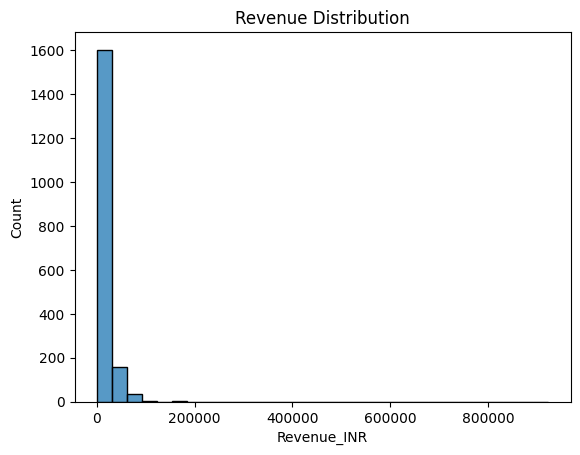

In [13]:
sns.histplot(
    df["Revenue_INR"],
    bins=30
)

plt.title(
    "Revenue Distribution"
)

plt.show()

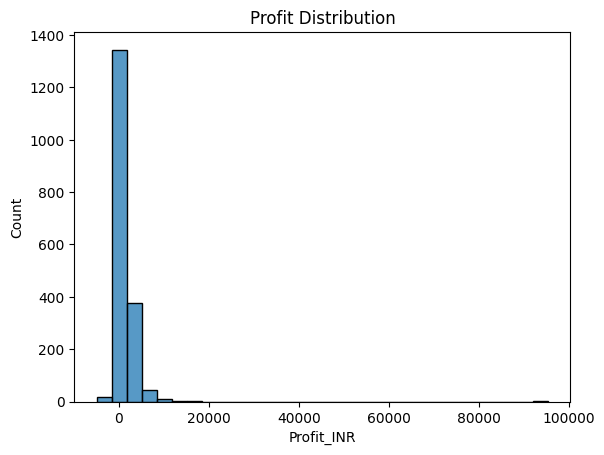

In [14]:
sns.histplot(
    df["Profit_INR"],
    bins=30
)

plt.title(
    "Profit Distribution"
)

plt.show()

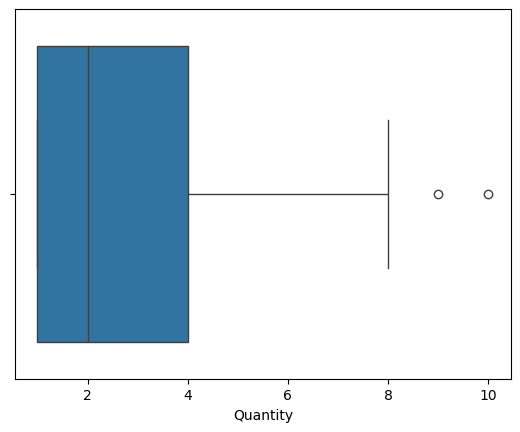

In [15]:
sns.boxplot(
    x=df["Quantity"]
)

plt.show()

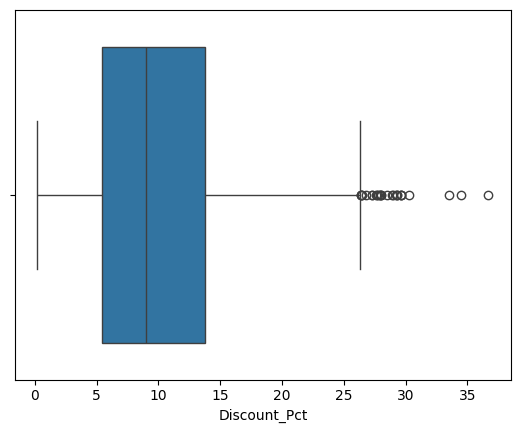

In [16]:
sns.boxplot(
    x=df["Discount_Pct"]
)

plt.show()

## Monthly Trend Analysis

In [19]:
df["Month"] = (
    df["Transaction_Date"].dt.month_name()
)

AttributeError: Can only use .dt accessor with datetimelike values

In [20]:
df["Month"] = (
    pd.to_datetime(df["Transaction_Date"]).dt.month_name()
)

In [22]:
df.head()

,Transaction_ID,Transaction_Date,Store,Region,Product_Category,Customer_Segment,Sales_Channel,Quantity,Discount_Pct,Revenue_INR,Profit_INR,Profit_Margin_Pct,Month
0,TXN100001,2025-02-02,Bengaluru Square,South,Beauty & Personal Care,Consumer,Store,2,25.5,2322.36,257.62,11.1,February
1,TXN100002,2025-10-10,Noida Hub,North,Home & Kitchen,Small Business,Online,2,9.5,9189.96,1927.81,21.0,October
2,TXN100003,2025-08-27,Noida Hub,North,Grocery,Consumer,Store,4,23.0,5816.07,-9.96,-0.2,August
3,TXN100004,2025-06-10,Bhubaneswar Plaza,East,Grocery,Small Business,Store,2,6.7,1399.29,38.75,2.8,June
4,TXN100005,2025-06-08,Kolkata Central,East,Home & Kitchen,Consumer,Store,1,3.8,3020.89,317.87,10.5,June


In [23]:
month_order = [
'January',
'February',
'March',
'April',
'May',
'June',
'July',
'August',
'September',
'October',
'November',
'December'
]

In [24]:
monthly_rev = (
    df.groupby("Month")
      ["Revenue_INR"]
      .sum()
      .reindex(month_order)
)

monthly_rev

,Revenue_INR
Month,
January,1726187.58
February,2332494.47
March,1765760.10
April,2477735.21
May,1460657.37
June,2443940.20
July,2164262.88
August,2429852.54
September,2231973.78


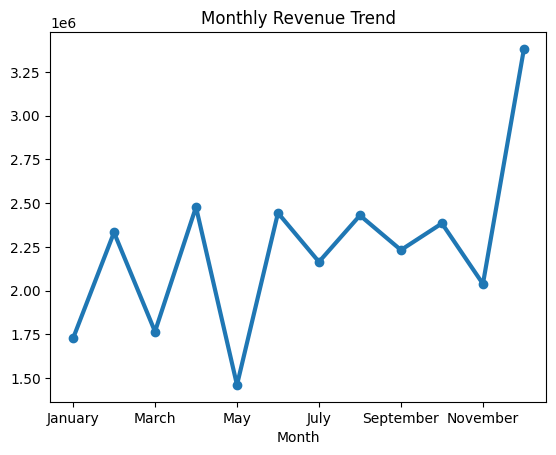

In [26]:
monthly_rev.plot(marker='o',linewidth=3)

plt.title("Monthly Revenue Trend")

plt.show()

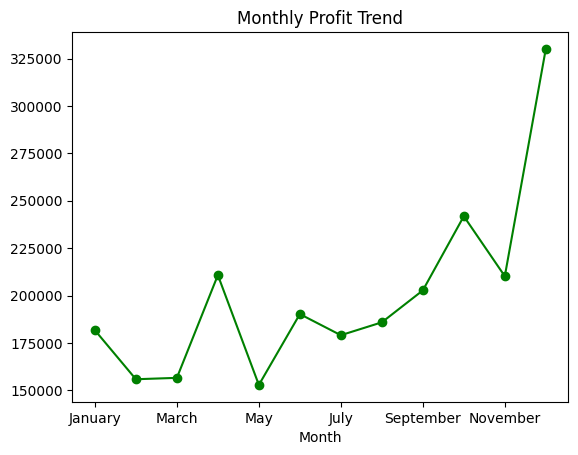

In [27]:
monthly_profit = (
    df.groupby("Month")
      ["Profit_INR"]
      .sum()
      .reindex(month_order)
)

monthly_profit.plot(
    marker='o',
    color='green'
)

plt.title("Monthly Profit Trend")

plt.show()

## CATEGORY ANALYSIS

In [28]:
category_rev = (
    df.groupby("Product_Category")
      ["Revenue_INR"]
      .sum()
      .sort_values()
)

category_rev

,Revenue_INR
Product_Category,
Beauty & Personal Care,1099900.41
Grocery,2055859.98
Apparel,2596309.02
Home & Kitchen,3791123.28
Electronics,7855112.71
Furniture,9438865.61


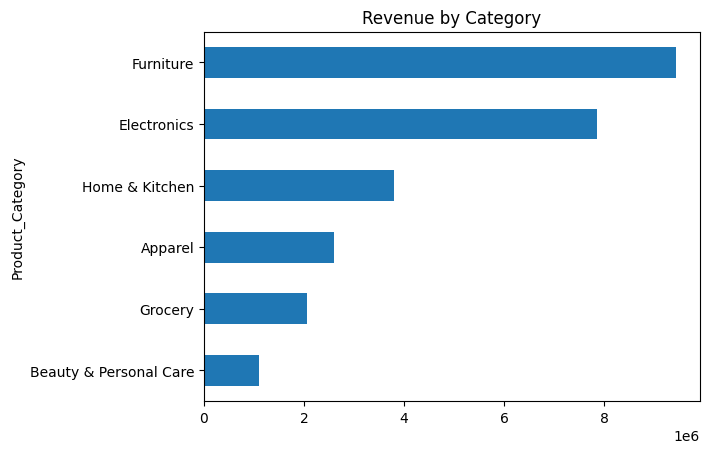

In [30]:
category_rev.plot(kind="barh")

plt.title("Revenue by Category")

plt.show()

In [31]:
category_profit = (
    df.groupby("Product_Category")
      ["Profit_INR"]
      .sum()
      .sort_values()
)

category_profit

,Profit_INR
Product_Category,
Grocery,89634.32
Beauty & Personal Care,227239.19
Furniture,310778.53
Apparel,435593.52
Home & Kitchen,545278.92
Electronics,789548.14


## Executive Question

### Highest Revenue?

### Highest Profit?

### Highest Margin?

## REGIONAL ANALYSIS

In [33]:
region_rev = (
    df.groupby("Region")
      ["Revenue_INR"]
      .sum()
      .sort_values()
)

region_rev

,Revenue_INR
Region,
Central,4029667.24
East,4192916.50
South,5258548.30
North,5498756.41
West,7857282.56


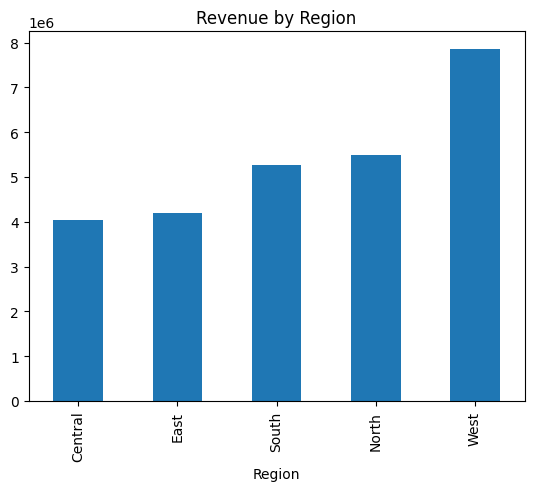

In [35]:
region_rev.plot(
    kind="bar"
)

plt.title(
    "Revenue by Region"
)

plt.show()

## Customer Segment Analysis

In [36]:
df.groupby(
    "Customer_Segment"
)["Revenue_INR"].sum()

,Revenue_INR
Customer_Segment,
Consumer,9714025.51
Corporate,7669445.51
Premium,3615007.80
Small Business,5670168.76


In [37]:
df.groupby(
    "Customer_Segment"
)["Profit_INR"].sum()

,Profit_INR
Customer_Segment,
Consumer,910424.58
Corporate,641600.46
Premium,287012.75
Small Business,543436.88


In [38]:
df.groupby(
    "Customer_Segment"
)["Profit_Margin_Pct"].mean()

,Profit_Margin_Pct
Customer_Segment,
Consumer,10.874186
Corporate,9.518783
Premium,11.230818
Small Business,11.114623


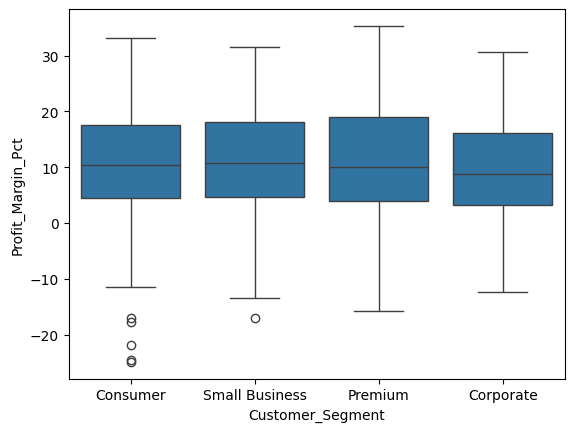

In [39]:
sns.boxplot(
    x="Customer_Segment",
    y="Profit_Margin_Pct",
    data=df
)

plt.show()

## Channel Analysis

In [41]:
df.groupby(
    "Sales_Channel"
)["Revenue_INR"].sum()

,Revenue_INR
Sales_Channel,
Online,10143988.35
Store,16693182.66


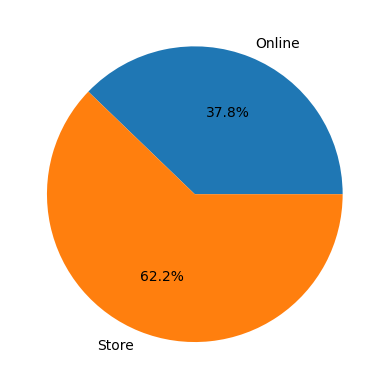

In [42]:
df.groupby(
    "Sales_Channel"
)["Revenue_INR"].sum().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.ylabel("")

plt.show()

## Discount Analysis

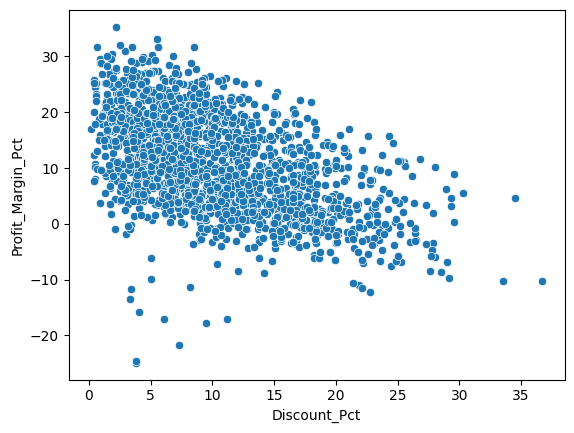

In [44]:
sns.scatterplot(
    data=df,
    x="Discount_Pct",
    y="Profit_Margin_Pct"
)

plt.show()

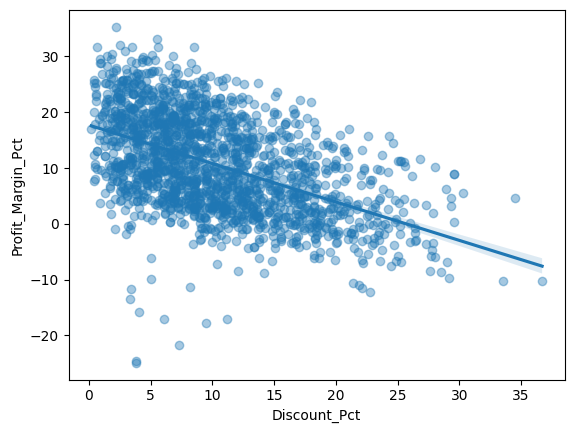

In [45]:
sns.regplot(
    data=df,
    x="Discount_Pct",
    y="Profit_Margin_Pct",
    scatter_kws={
        "alpha":0.4
    }
)

plt.show()

In [47]:
df["Discount_Bucket"] = pd.cut(
    df["Discount_Pct"],
    bins=[0,5,10,15,20,25,50]
)

In [48]:
df.groupby(
    "Discount_Bucket"
)["Profit_Margin_Pct"].mean()

/tmp/ipykernel_1285/293002295.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(


,Profit_Margin_Pct
Discount_Bucket,
"(0, 5]",15.622772
"(5, 10]",12.714975
"(10, 15]",8.723267
"(15, 20]",5.666805
"(20, 25]",2.281000
"(25, 50]",0.917073


## Correlation Matrix

In [49]:
numerics = (
    df.select_dtypes(
        include=np.number
    )
)

In [50]:
corr = numerics.corr()

corr

,Quantity,Discount_Pct,Revenue_INR,Profit_INR,Profit_Margin_Pct
Quantity,1.000000,0.034539,0.292656,0.252880,-0.024520
Discount_Pct,0.034539,1.000000,0.046936,-0.217209,-0.495597
Revenue_INR,0.292656,0.046936,1.000000,0.742318,-0.097090
Profit_INR,0.252880,-0.217209,0.742318,1.000000,0.269555
Profit_Margin_Pct,-0.024520,-0.495597,-0.097090,0.269555,1.000000


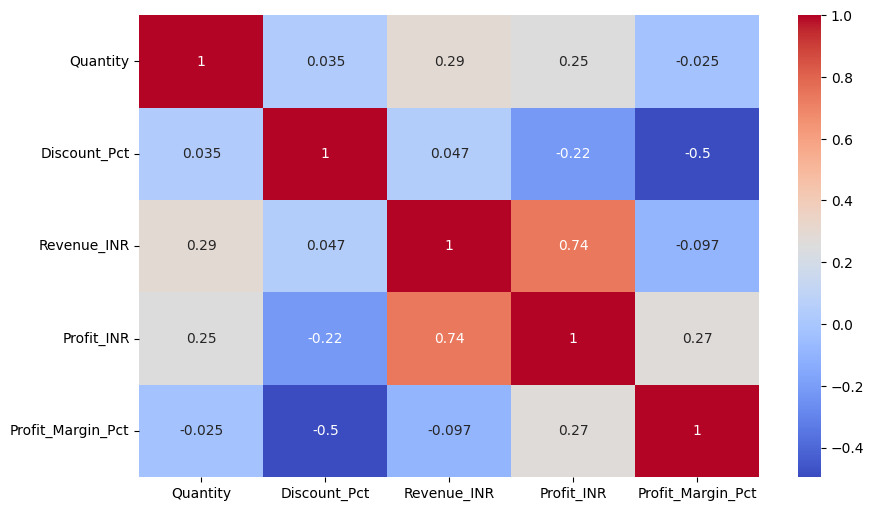

In [51]:
plt.figure(
    figsize=(10,6)
)

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.show()

## Bi-Variate Analysis

In [52]:
pivot = pd.pivot_table(
    df,
    values="Profit_INR",
    index="Region",
    columns="Product_Category",
    aggfunc="sum"
)

pivot

Product_Category,Apparel,Beauty & Personal Care,Electronics,Furniture,Grocery,Home & Kitchen
Region,,,,,,
Central,69593.66,29699.65,87341.98,61192.52,13983.66,97360.97
East,71373.56,38330.46,108645.07,43523.08,14657.10,89667.98
North,94321.32,62570.63,131029.66,57488.87,22187.33,143799.48
South,69886.43,43022.81,126988.25,71491.80,18493.29,112559.43
West,130418.55,53615.64,335543.18,77082.26,20312.94,101891.06


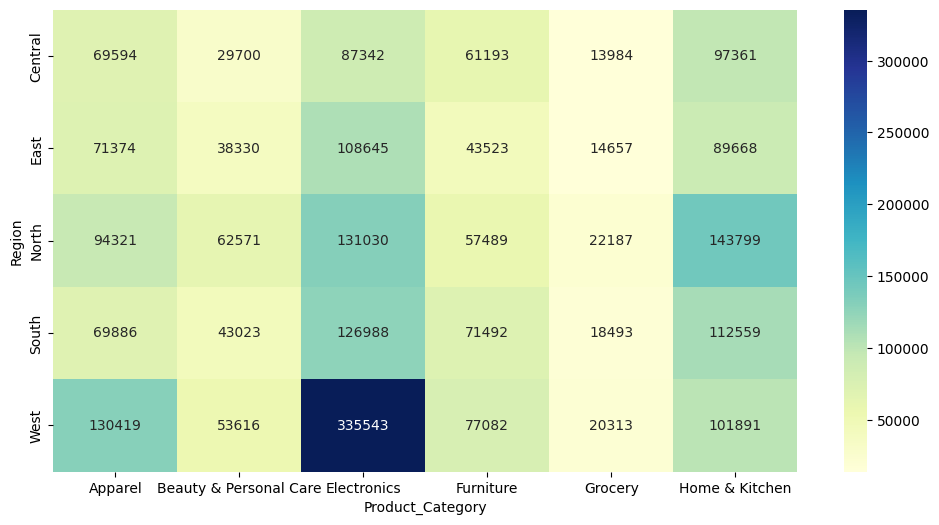

In [53]:
plt.figure(
    figsize=(12,6)
)

sns.heatmap(
    pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.show()

## Loss Making Categories

In [54]:
losses = df[df["Profit_INR"] < 0]

In [55]:
losses.groupby(
    "Product_Category"
)["Profit_INR"].sum()

,Profit_INR
Product_Category,
Apparel,-1850.13
Beauty & Personal Care,-8888.18
Electronics,-8631.47
Furniture,-49751.40
Grocery,-9548.47
Home & Kitchen,-8243.17


In [56]:
losses.groupby(
    "Region"
)["Profit_INR"].sum()

,Profit_INR
Region,
Central,-12382.13
East,-12276.45
North,-19749.88
South,-14876.87
West,-27627.49


## Executive Dashboard

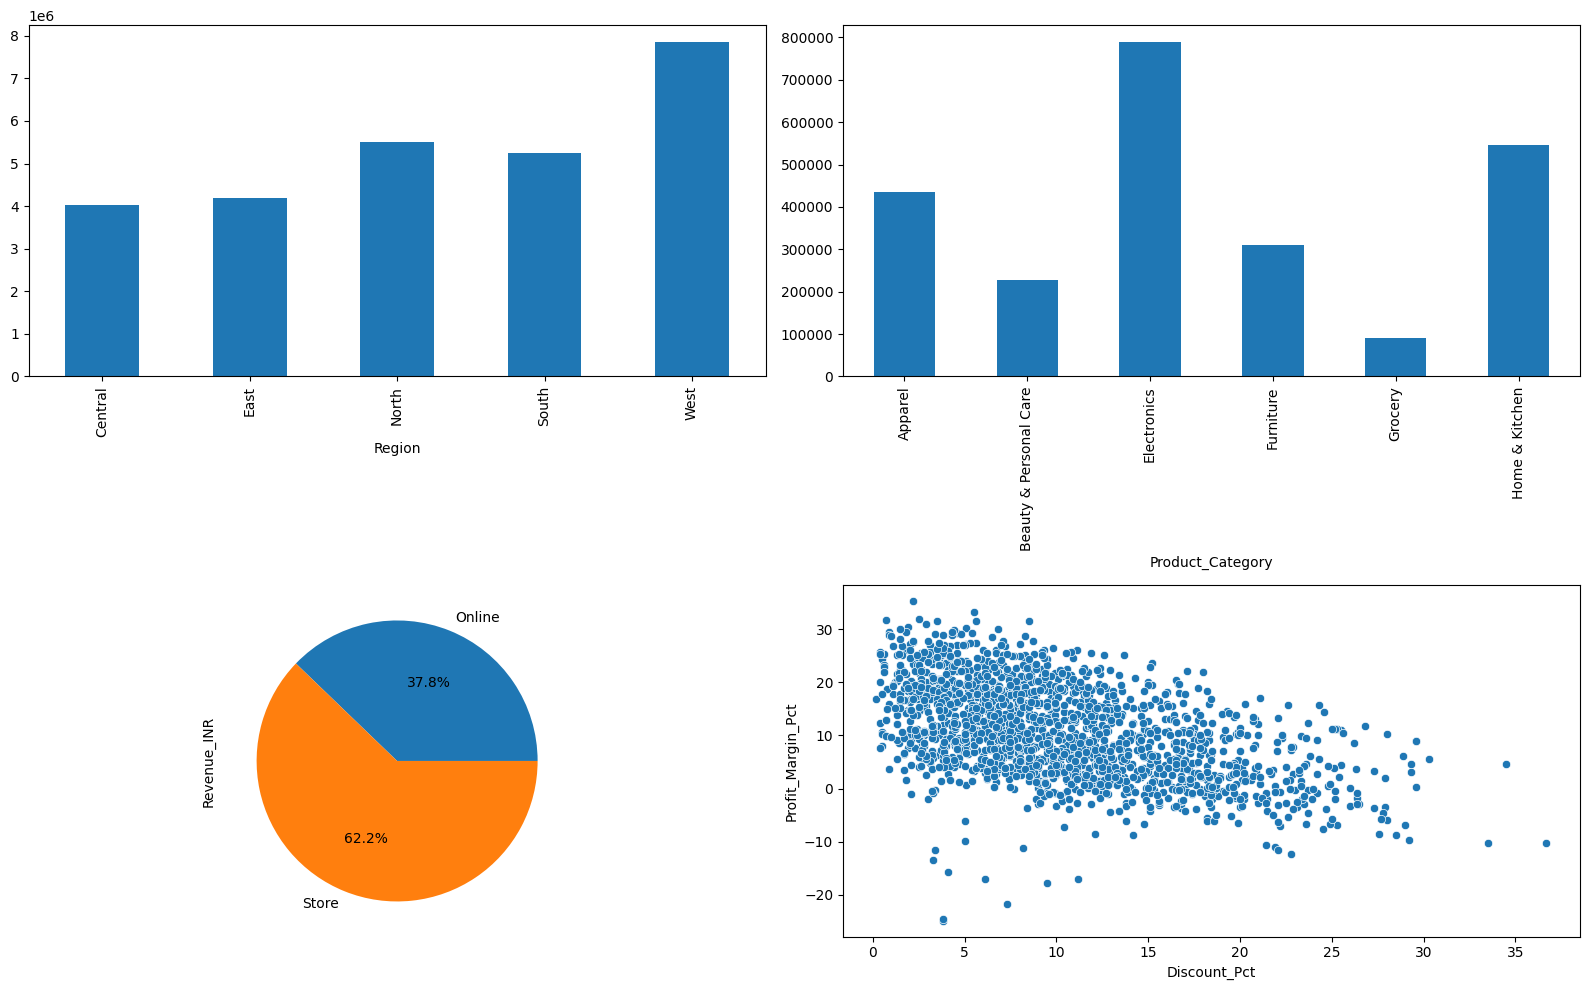

In [57]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(16,10)
)

df.groupby("Region")[
    "Revenue_INR"
].sum().plot(
    kind="bar",
    ax=axes[0,0]
)

df.groupby("Product_Category")[
    "Profit_INR"
].sum().plot(
    kind="bar",
    ax=axes[0,1]
)

df.groupby("Sales_Channel")[
    "Revenue_INR"
].sum().plot(
    kind="pie",
    autopct="%1.1f%%",
    ax=axes[1,0]
)

sns.scatterplot(
    x="Discount_Pct",
    y="Profit_Margin_Pct",
    data=df,
    ax=axes[1,1]
)

plt.tight_layout()

plt.show()

## CEO Challenge
1. Best region?
2. Best category?
3. Most profitable segment?
4. Does discount hurt margin?
5. Where should Rs.10 crore be invested?